# Лекция 6. Нейросеть вместо таблицы: DQN

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/IlyaChichkanov/Reinforcement-learning/blob/main/06-dqn/lecture/lecture.ipynb)

**Главный вопрос сегодня: как учить Q-функцию, когда состояний бесконечно много, — и зачем для этого нужны буфер опыта и целевая сеть?**

Карта пути. Q-learning (лекции 3 и 4) хранил таблицу $Q$: по числу на каждую пару «состояние, действие». Сегодня среда — CartPole из лекции 5, её состояние — четыре непрерывных числа. Таблица на сетке учит каждую клетку отдельно и до соседних не дотягивается. Нейросеть учит похожие состояния вместе — но если учить её бездумно, оценки разлетаются. Два приёма это чинят: буфер опыта и целевая сеть. Вместе это **DQN** (Deep Q-Network) — алгоритм, который в 2015 году научился играм Atari прямо по пикселям экрана.

Лекция устроена как прошлые: раздел начинается с вопроса, на который мы **голосуем всей аудиторией**, и только потом проверяем ответ запуском. Вопросы и песочница — на странице-спутнике, откройте её на телефоне:

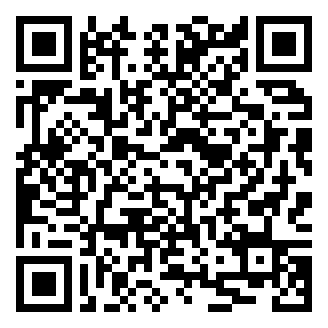

[ilyachichkanov.github.io/Reinforcement-learning/lecture06.html](https://ilyachichkanov.github.io/Reinforcement-learning/lecture06.html)

| | Раздел | Минут |
|---|---|---|
| 1 | 🔁 Таблица не учит соседей | 8 |
| 2 | Q-сеть: один шаг учит все похожие состояния | 14 |
| 3 | Буфер опыта: учимся на перемешанных переходах | 16 |
| 4 | Почему оценки разлетаются: смертельная триада | 14 |
| 5 | Целевая сеть: неподвижная мишень. Это и есть DQN | 24 |
| 6 | ⏱ Улучшения DQN | 6 |
| 7 | Итоги и где это работает | 8 |

Пометки: **🔁** — вспоминаем пройденное, **⏱** — резерв. Первая строка раздела — **главная идея**, блоки **«Простыми словами»** пересказывают формулы без формул. Служебный код — в `dqn_plots.py`; читать его не нужно. Ноутбук считается около 10 минут, вывод сохранён; `QUICK = True` в следующей ячейке — быстрый прогон с другими числами.

In [1]:
QUICK = False                                     # True — один запуск и 200 эпизодов вместо трёх и 300
SEEDS = range(1) if QUICK else range(3)
EPISODES = 200 if QUICK else 300

# Служебные модули. В репозитории они лежат рядом; в Google Colab скачиваются заново при каждом запуске.
import pathlib, sys, urllib.error, urllib.request
RAW = "https://raw.githubusercontent.com/IlyaChichkanov/Reinforcement-learning/"
for name, folder in (("dqn_plots", "06-dqn/lecture"), ("cartpole_plots", "05-policy-gradient/seminar")):
    local = pathlib.Path("../..") / folder / f"{name}.py"
    if local.exists():
        sys.path.append(str(local.parent))
        continue
    for branch in ("main", "claude/lecture06"):                   # пока лекция не влита в main — из ветки
        try:
            urllib.request.urlretrieve(f"{RAW}{branch}/{folder}/{name}.py", f"{name}.py"); break
        except urllib.error.HTTPError:
            continue
import importlib.util, subprocess
for package in ("gymnasium", "torch"):
    if importlib.util.find_spec(package) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

In [2]:
import time
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
import torch
from dqn_plots import *                          # make_cartpole, GridTable, train_table, карты и графики
from cartpole_plots import draw_cartpole, animate_cartpole
start_time = time.time()

## 1. 🔁 Таблица не учит соседей

**Главная идея: клетка таблицы учится, только когда агент в неё попал, — соседние состояния учатся порознь, и большинство клеток не учится вовсе.**

**Среда — CartPole** из лекции 5:

* *состояние* — четыре числа: положение тележки $x$, её скорость $\dot x$, угол шеста $\varphi$ и его угловая скорость $\dot\varphi$;
* *действия* — два: толкнуть тележку ← или →;
* *награда* — $+1$ за каждый шаг, пока шест стоит;
* *конец эпизода* — шест отклонился больше чем на 12°, тележка уехала за край или прошло 500 шагов.

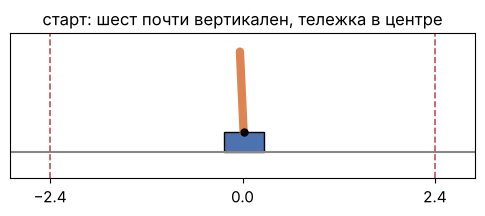

In [3]:
env = make_cartpole()
s, _ = env.reset(seed=0)
draw_cartpole(s, title="старт: шест почти вертикален, тележка в центре")
plt.show()

Чтобы завести таблицу $Q$, каждое из четырёх чисел режем на 6 отрезков: сетка из $6^4 = 1296$ клеток, в таблице $1296 \times 2$ чисел. Посмотрим на сетку со стороны угла и угловой скорости и сыграем один эпизод случайной стратегией.

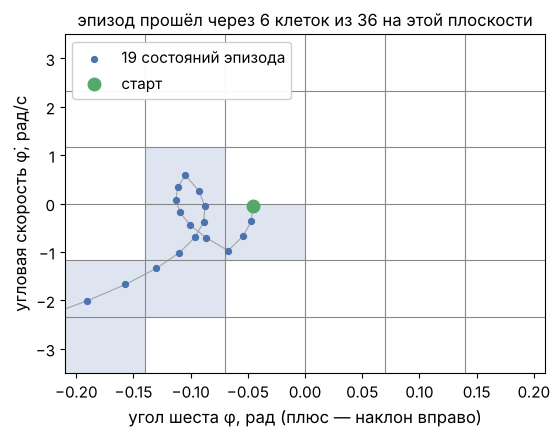

In [4]:
table = GridTable(bins=6)
states = random_episode(seed=0)                   # список состояний одного эпизода случайной стратегии
plot_grid_episode(table, states)
plt.show()

За эпизод агент побывал в 6 клетках из 36 на этой плоскости — и только их строки таблица может обновить. Два состояния по разные стороны линии сетки — разные строки, хотя шест в них стоит почти одинаково.

Обучим таблицу Q-learning из лекций 3–4 (`train_table`: $\alpha = 0.1$, $\gamma = 0.99$, ε-жадный выбор, $\varepsilon$ от 1 до 0.05 за 10 000 шагов), 300 эпизодов.

**Вопрос 1 (голосуем).** Сколько клеток из 1296 получат хотя бы одно обновление?

* **A.** почти все;
* **B.** около половины;
* **C.** около 10 %;
* **D.** только клетки рядом со стартом.

клеток с обновлениями: 8% от 1296;   шест в последних 50 эпизодах: [61. 43. 54.] шагов
★ клетка обновлялась 325 раз, V = 6.1;   ☆ соседняя клетка: 0 обновлений, V = 0.0


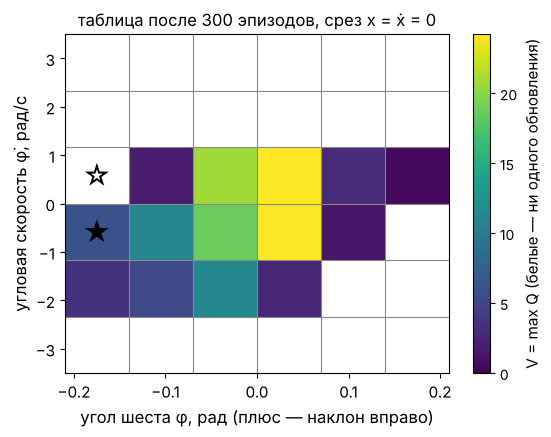

In [5]:
results = [train_table(table, seed=k, episodes=EPISODES) for k in SEEDS]
lengths_table = np.array([lengths for _, lengths, _ in results])
Q_table, _, visits = results[0]
print(f"клеток с обновлениями: {np.mean([(v > 0).mean() for _, _, v in results]):.0%} от 1296;"
      f"   шест в последних 50 эпизодах: {lengths_table[:, -50:].mean(axis=1).round(0)} шагов")

V, N = table_slice(Q_table, table, visits, x=0.0, x_dot=0.0)       # срез таблицы: тележка в центре и стоит
pair = neighbour_pair(V, N)
(i, j), (a, b) = pair
print(f"★ клетка обновлялась {N[a, b]} раз, V = {V[a, b]:.1f};   ☆ соседняя клетка: 0 обновлений, V = {V[i, j]:.1f}")
plot_table_values(V, N, table, pair=pair, title=f"таблица после {EPISODES} эпизодов, срез x = ẋ = 0")
plt.show()

Ответ **C — около 10 %**: обновления получили 8 % клеток, остальные хранят нули. Шест стоит 43–61 шагов.

**Почему так выходит.** На карте — острова: клетка учится, только когда агент в неё попал. Клетка ★ обновлялась 325 раз и знает $V \approx 6$; соседняя ☆, где шест стоит почти так же, не обновлялась ни разу и знает ноль. Сетку можно нарезать умнее, но это подсказка человека, который заранее знает, что важно. А в игре, где состояние — кадр $84 \times 84$ пикселя, состояния не повторяются никогда.

> **Простыми словами.** Таблица — как ученик, который заучивает ответ на каждый экзаменационный билет отдельно: на билет, которого он не видел, он не ответит, даже если тот почти совпадает с выученным.

**Одной строкой:** таблица учит каждую клетку отдельно — там, где агент не был, она не знает ничего.

## 2. Q-сеть: один шаг учит все похожие состояния

**Главная идея: сеть считает $Q$ всех состояний одними и теми же весами, поэтому шаг обучения в одном состоянии сдвигает оценки всех похожих. Это называют обобщением.**

Заменим таблицу нейросетью: на вход — состояние (4 числа), на выход — два числа $Q(s, \leftarrow)$ и $Q(s, \rightarrow)$. Все веса сети обозначим $\theta$, как в лекции 5. Действие выбираем, как по таблице: ε-жадно, с наибольшим $Q$.

In [6]:
def make_qnet(seed=0):
    # Q-сеть: состояние (4 числа) -> оценки двух действий (Q(s, ←), Q(s, →)); её веса — параметры θ
    torch.manual_seed(seed)
    return torch.nn.Sequential(torch.nn.Linear(4, 64), torch.nn.ReLU(),
                               torch.nn.Linear(64, 64), torch.nn.ReLU(),
                               torch.nn.Linear(64, 2))

def epsilon_greedy(qnet, s, eps, rng):
    # с вероятностью ε — случайное действие, иначе действие с наибольшим Q
    if rng.random() < eps:
        return int(rng.integers(2))
    with torch.no_grad():
        return int(qnet(torch.as_tensor(s)).argmax())

qnet = make_qnet()
print("параметров θ:", sum(p.numel() for p in qnet.parameters()))

параметров θ: 4610


Учим сеть, как таблицу, только вместо «сдвинуть клетку» — шаг градиента. Цель — та же, что у Q-learning:

$$
y \;=\; r + \gamma\,(1 - \text{конец})\, \max_{a'} Q_\theta(s', a'), \qquad \text{loss} \;=\; \big(y - Q_\theta(s, a)\big)^2 .
$$

Множитель $(1 - \text{конец})$ равен нулю, если на этом шаге эпизод кончился: будущих наград нет. Цель $y$ — **число**: мы двигаем оценку к цели, а не цель к оценке, поэтому градиент через $y$ не пропускаем (`torch.no_grad()`).

Переход — кортеж $(s, a, r, s', \text{конец})$. Три короткие функции ниже работают со **списком переходов** — сегодня из одного, в разделе 3 из 64: `to_tensors` раскладывает список на пять тензоров, `td_targets` считает цель $y$ для каждого перехода, `q_of` достаёт $Q_\theta(s_t, a_t)$ — из строки $t$ таблицы «переход × действие» столбец сыгранного действия, как `log_probs_of` в лекции 5.

In [7]:
def to_tensors(transitions):
    # список переходов (s, a, r, s′, конец) -> пять тензоров: S (n × 4), A (n), R (n), S2 (n × 4), D (n)
    return [torch.as_tensor(np.array(column)) for column in zip(*transitions)]

def td_targets(net, R, S2, D, gamma=0.99):
    # цель y для каждого перехода: тензор из n чисел; net(S2) — таблица n × 2, max по действиям; без градиента
    with torch.no_grad():
        return R + gamma * (1 - D) * net(S2).max(dim=1).values

def q_of(qnet, S, A):
    # Q_θ(s_t, a_t) для каждого перехода: тензор из n чисел — из строки t таблицы qnet(S) столбец A[t]
    return qnet(S)[torch.arange(len(A)), A]

def q_max(net, s):
    # max_a Q(s, a) для одного состояния — просто число
    with torch.no_grad():
        return net(torch.as_tensor(s)).max().item()

transition = (s, 1, np.float32(1.0), s, np.float32(0))          # пример: один переход из стартового состояния
S, A, R, S2, D = to_tensors([transition])
print("S:", tuple(S.shape), " A:", A.tolist(), " цель y:", td_targets(qnet, R, S2, D).numpy().round(3),
      " Q(s, a):", q_of(qnet, S, A).detach().numpy().round(3))

S: (1, 4)  A: [1]  цель y: [1.135]  Q(s, a): [0.002]


**Вопрос 2 (голосуем).** Состояние ★: шест наклонён вправо на 0.05 рад и падает вправо со скоростью 0.5 рад/с, тележка в центре. Делаем **один** шаг градиента, сдвигая $Q(★, \rightarrow)$ к цели. Где изменится $Q(\cdot, \rightarrow)$ на плоскости «угол — угловая скорость»?

* **A.** только в клетке ★, как у таблицы;
* **B.** в небольшом пятне вокруг ★;
* **C.** почти на всей плоскости;
* **D.** нигде заметно: шаг слишком маленький.

сдвиг Q(·, →) в ★: +1.15;   наименьший сдвиг на плоскости: +0.87


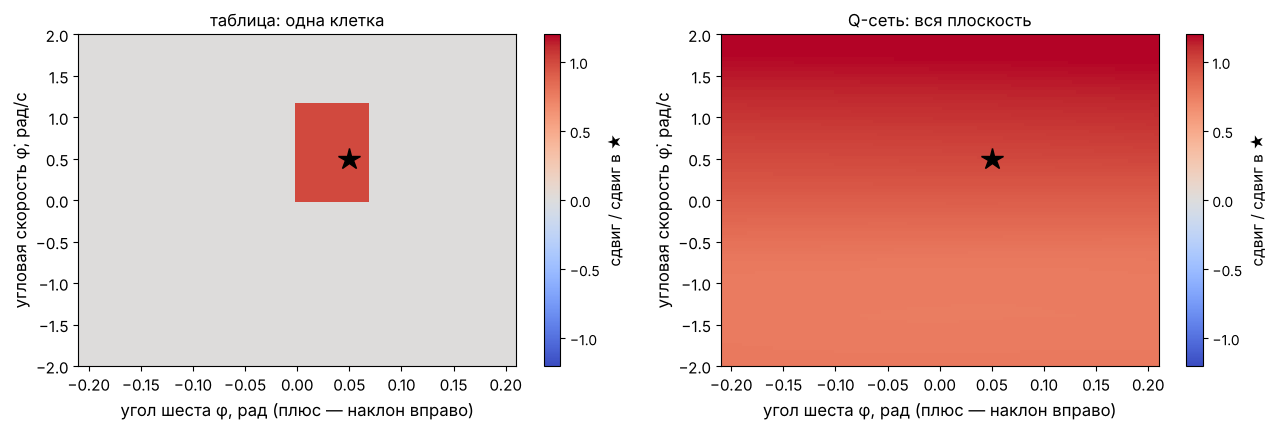

In [8]:
star = np.array([0.0, 0.0, 0.05, 0.5], dtype=np.float32)   # состояние ★: x, ẋ, φ, φ̇
points, shape = plane()                                     # точки всей плоскости (φ, φ̇)
shift, shift_star = footprint_net(make_qnet(), star, points, action=1, target=50.0, lr=0.01)   # сдвиг Q(·, →) в каждой точке
print(f"сдвиг Q(·, →) в ★: {shift_star:+.2f};   наименьший сдвиг на плоскости: {shift.min():+.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
plot_footprint(footprint_table(table, star, points), shape, star, ax=axes[0], title="таблица: одна клетка")
plot_footprint(shift / shift_star, shape, star, ax=axes[1], title="Q-сеть: вся плоскость")
plt.tight_layout(); plt.show()

Ответ **C — почти на всей плоскости**: $Q(\cdot, \rightarrow)$ сдвинулась на +1.15 в самой ★ и не меньше чем на +0.87 в любой точке плоскости — даже там, где шест падает в другую сторону. У таблицы сдвинулась одна клетка.

**Почему так выходит.** Все состояния сеть считает одними и теми же весами $\theta$: шаг сдвигает веса, а через них — оценки всех состояний сразу. Это польза: сети не нужно побывать в каждом состоянии. И риск: оценка сдвинулась и там, где данных не было, — об этом раздел 3.

> **Простыми словами.** Сеть — ученик, который понял правило, а не заучил билеты: разобрал одну задачу — стал лучше решать похожие. И хуже — непохожие, если правило понял неверно.

Соберём простейшее обучение: шаг в среде → один переход → один шаг градиента, как таблица в разделе 1. Через 300 эпизодов сравним, что выучили таблица и сеть.

шест в эпизодах 100–300: таблица [34. 32. 31.],  Q-сеть [83. 75. 52.] шагов


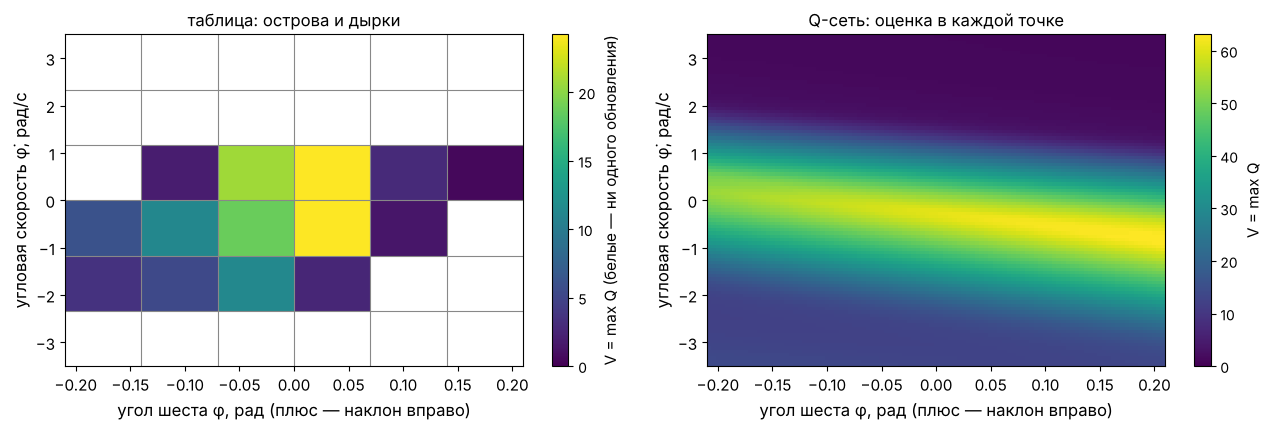

In [9]:
def train_simple(seed, episodes=EPISODES, lr=1e-3):
    # Q-сеть учится после каждого шага на этом же переходе; возвращает длины эпизодов, оценки старта и сеть
    rng, env, qnet = np.random.default_rng(seed), make_cartpole(), make_qnet(seed)
    opt = torch.optim.Adam(qnet.parameters(), lr=lr)
    step, lengths, q_start = 0, [], []
    for episode in range(episodes):
        s, _ = env.reset(seed=seed * 10_000 + episode)
        q_start.append(q_max(qnet, s))                                   # во что сеть верит на старте эпизода
        for t in range(1, 501):
            # 1. шаг в среде: ε падает от 1 до 0.01 за первые 5000 шагов
            a = epsilon_greedy(qnet, s, eps=max(0.01, 1 - step / 5000), rng=rng)
            s2, r, terminated, truncated, _ = env.step(a)
            transition = (s, a, np.float32(r), s2, np.float32(terminated))
            # 2. шаг градиента на этом одном переходе
            S, A, R, S2, D = to_tensors([transition])
            loss = ((td_targets(qnet, R, S2, D) - q_of(qnet, S, A)) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            step += 1; s = s2
            if terminated or truncated:
                break
        lengths.append(t)
    return np.array(lengths), np.array(q_start), qnet

runs = {"по шагу подряд": [train_simple(seed) for seed in SEEDS]}
lengths = {"по шагу подряд": np.array([run[0] for run in runs["по шагу подряд"]])}
q_start = {"по шагу подряд": np.array([run[1] for run in runs["по шагу подряд"]])}
print(f"шест в эпизодах 100–{EPISODES}: таблица {lengths_table[:, 100:].mean(axis=1).round(0)},"
      f"  Q-сеть {lengths['по шагу подряд'][:, 100:].mean(axis=1).round(0)} шагов")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
plot_table_values(V, N, table, ax=axes[0], title="таблица: острова и дырки", vmax=max(V.max(), 1))
plot_q_plane(q_plane(runs["по шагу подряд"][0][2]), ax=axes[1], title="Q-сеть: оценка в каждой точке")
plt.tight_layout(); plt.show()

Сеть выучила оценку **на всей плоскости**, а не в островах. Но шест она держит пока недолго: 52–83 шагов — вдвое дольше таблицы и далеко от 500. Обобщение есть, а учится сеть медленно: каждый шаг градиента видит один переход, почти такой же, как предыдущий. Что с этим делать — разделы 3–5.

**Одной строкой:** сеть обобщает — один шаг учит все похожие состояния, оценка есть везде; осталось научить её быстро и не сломать.

## 3. Буфер опыта: учимся на перемешанных переходах

**Главная идея: сеть учится на случайных пачках из журнала всех прошлых переходов, а не на последнем шаге, — обучение идёт быстрее. Но оценки $Q$ при этом разлетаются.**

**Буфер опыта** (experience replay) — журнал переходов $(s, a, r, s', \text{конец})$ на 50 000 записей. Каждый шаг в среде дописывает переход в конец, самый старый при переполнении выбрасывается, а шаг градиента делается на **пачке** — 64 переходах, взятых из журнала случайно.

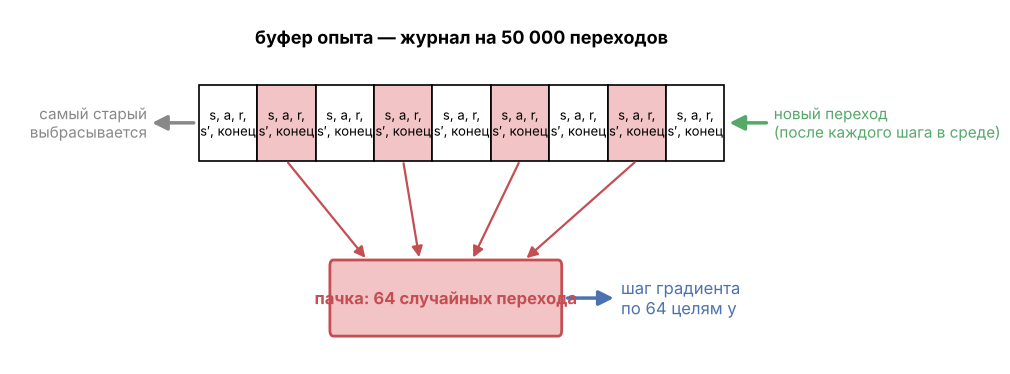

In [10]:
draw_replay_scheme()
plt.show()

В пачке — переходы из разных эпизодов и ситуаций, и каждый переход за обучение попадает в пачки много раз. По шагу подряд сеть видела один переход — последний, почти такой же, как предыдущий. Учиться на старых переходах, собранных прежней стратегией, можно: Q-learning — off-policy (лекция 4).

> **Простыми словами.** Повторяешь перемешанные карточки из всех тем, а не двести задач подряд на одну.

В коде журнал — обычная очередь `deque(maxlen=50_000)`, пачка — строка в блоке 2 функции `train_qnet`. Остальное — тот же цикл, что `train_simple`. Флаг `target` и `soft_update` — раздел 5, пока они выключены.

In [11]:
def soft_update(target_net, qnet, tau):
    # θ̄ ← (1 − τ) θ̄ + τ θ: копия на долю τ догоняет основную сеть (раздел 5)
    with torch.no_grad():
        for p_bar, p in zip(target_net.parameters(), qnet.parameters()):
            p_bar.mul_(1 - tau).add_(tau * p)


def train_qnet(seed, replay, target, episodes=EPISODES, lr=1e-3, batch=64, tau=0.01):
    # replay — учиться на пачке из журнала (иначе на последнем переходе); target — цель считает копия сети
    # возвращает длины эпизодов, оценки старта, след первых 4000 шагов (для картинки раздела 5) и сеть
    rng, env = np.random.default_rng(seed), make_cartpole()
    qnet, target_net = make_qnet(seed), make_qnet(seed)             # основная сеть и её копия
    opt = torch.optim.Adam(qnet.parameters(), lr=lr)
    buffer = deque(maxlen=50_000)                                     # журнал переходов
    step, lengths, q_start, trace = 0, [], [], []
    s0 = env.reset(seed=seed * 10_000)[0]                             # стартовое состояние — для следа
    for episode in range(episodes):
        s, _ = env.reset(seed=seed * 10_000 + episode)
        q_start.append(q_max(qnet, s))
        for t in range(1, 501):
            # 1. шаг в среде, переход — в журнал
            a = epsilon_greedy(qnet, s, eps=max(0.01, 1 - step / 5000), rng=rng)
            s2, r, terminated, truncated, _ = env.step(a)
            buffer.append((s, a, np.float32(r), s2, np.float32(terminated)))
            # 2. на чём учимся: список из 64 случайных переходов — или из одного последнего
            picked = [buffer[i] for i in rng.integers(len(buffer), size=batch)] if replay else [buffer[-1]]
            S, A, R, S2, D = to_tensors(picked)
            # 3. цель и шаг градиента: цель считает копия (target) или сама сеть
            y = td_targets(target_net if target else qnet, R, S2, D)
            loss = ((y - q_of(qnet, S, A)) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            # 4. копия догоняет основную сеть (раздел 5)
            if target:
                soft_update(target_net, qnet, tau)
            if step < 4000:
                trace.append((q_max(qnet, s0), q_max(target_net, s0)))   # след для картинки раздела 5
            step += 1; s = s2
            if terminated or truncated:
                break
        lengths.append(t)
    return np.array(lengths), np.array(q_start), np.array(trace), qnet

**Вопрос 3 (голосуем).** Та же сеть, те же 300 эпизодов, но шаг обучения — на пачке из буфера. Что изменится по сравнению с обучением по шагу подряд?

* **A.** шест будет стоять дольше, и оценки $Q$ останутся разумными;
* **B.** шест будет стоять дольше, но оценки $Q$ вырастут до тысяч;
* **C.** ничего не изменится;
* **D.** станет хуже: старые переходы собраны плохой стратегией.

Справа на картинке — оценка старта. Больше 100 она быть не может: даже если шест простоит вечно, сумма наград $1 + 0.99 + 0.99^2 + \dots = 1 / (1 - 0.99) = 100$.

по шагу подряд  шест в эпизодах 100–300: [83. 75. 52.] шагов,  наибольшая оценка старта: [75. 98. 58.]
буфер           шест в эпизодах 100–300: [348. 331. 206.] шагов,  наибольшая оценка старта: [  1584.   3698. 210279.]


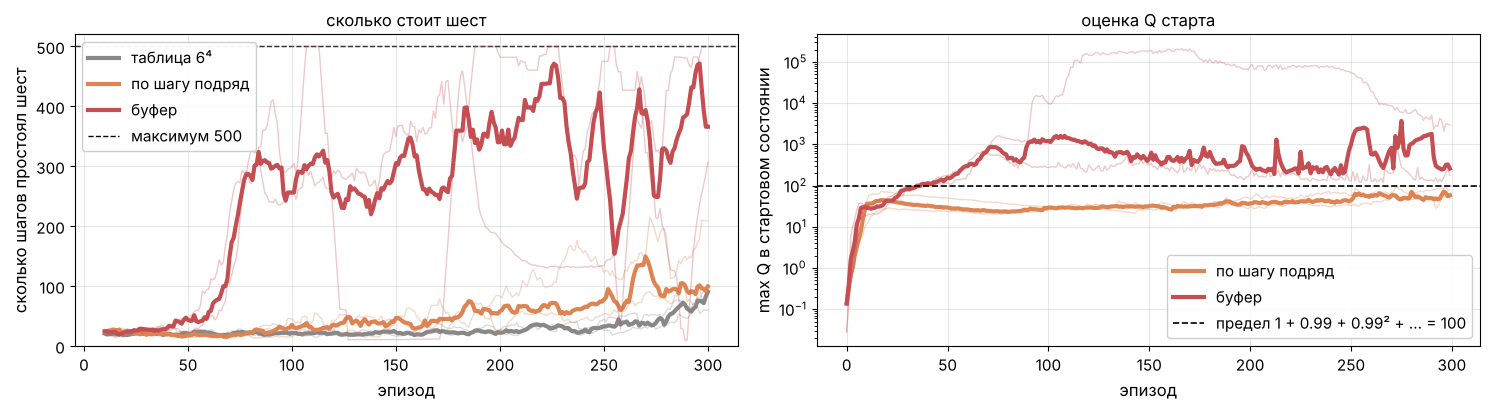

In [12]:
runs["буфер"] = [train_qnet(seed, replay=True, target=False) for seed in SEEDS]
lengths["буфер"] = np.array([run[0] for run in runs["буфер"]])
q_start["буфер"] = np.array([run[1] for run in runs["буфер"]])
for name in ("по шагу подряд", "буфер"):
    print(f"{name:15s} шест в эпизодах 100–{EPISODES}: {lengths[name][:, 100:].mean(axis=1).round(0)} шагов,"
          f"  наибольшая оценка старта: {np.abs(q_start[name]).max(axis=1).round(0)}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
plot_runs({"таблица 6⁴": lengths_table, **lengths}, ax=axes[0], title="сколько стоит шест")
plot_q_start(q_start, ax=axes[1], title="оценка Q старта")
plt.tight_layout(); plt.show()

Ответ **B — шест стоит дольше, но оценки $Q$ вырастают до тысяч**. С буфером шест стоит 206–348 шагов в эпизодах 100–300 против 52–83 по шагу подряд. Но оценка старта во всех трёх запусках ушла далеко за предел 100: до 1584, 3698 и 210 279. По шагу подряд она осталась ниже предела: 58–98.

**Почему оценки разлетаются.** Цель $y = r + \gamma \max Q_\theta(s')$ считает та же сеть, которую мы учим: шаг поднимает $Q_\theta(s, a)$, а из-за обобщения — и $Q_\theta(s')$, то есть саму цель. Следующий шаг тянется к новой, более высокой цели, и так по кругу. Почему без буфера этого не случилось — раздел 4.

> **Простыми словами.** Это как догонять собственную тень: шагаешь к ней — она отодвигается.

**Одной строкой:** буфер перемешивает данные и ускоряет обучение, но оценки $Q$ при нём уходят далеко за возможный предел.

## 4. Почему оценки разлетаются: смертельная триада

**Главная идея: оценка разлетается до бесконечности даже при нулевых наградах, если сойдутся три условия — общие веса, своя оценка в цели и данные не той стратегии, которую оцениваем. Буфер добавил Q-сети третье.**

Самый маленький пример, на котором это видно целиком (Саттон и Барто, раздел 11.2):

| | |
|---|---|
| **состояния** | два: из 1 агент переходит в 2, из 2 эпизод кончается; обе награды 0, настоящие ценности — нули |
| **оценка** | одна ручка $w$ на обе: $\hat v(1) = w$, $\hat v(2) = 2w$ — как у сети, где один вес двигает много оценок |
| **данные** | только переходы $1 \to 2$: другая стратегия до конца не доходила |
| **обновление** | как в разделе 2: цель $= 0 + \gamma\, \hat v(2) = 1.8\,w$, шаг $w \leftarrow w + \alpha\,(1.8\,w - w)$ |

Нарисуем пример и первые три шага обновления.

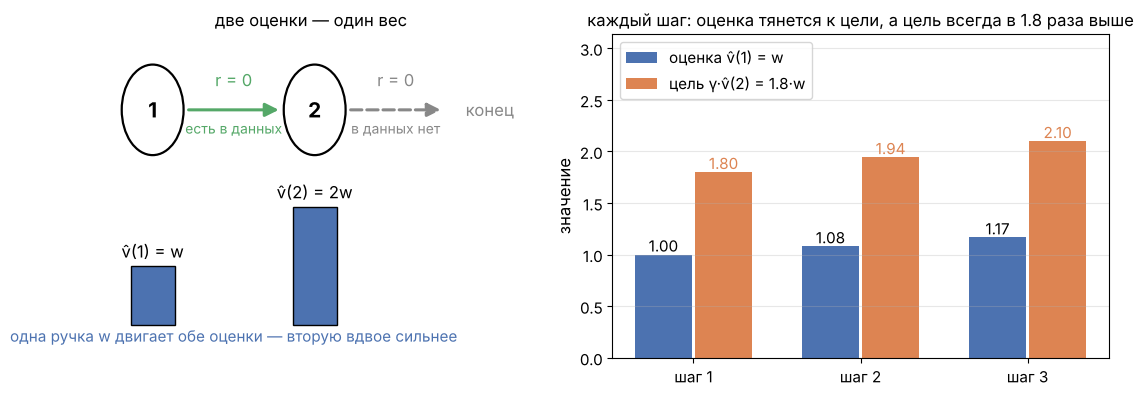

In [13]:
draw_two_states(gamma=0.9, alpha=0.1, steps=3)
plt.show()

**Вопрос 4 (голосуем).** Начинаем с $w = 1$, $\gamma = 0.9$, $\alpha = 0.1$ и делаем 100 таких шагов. Что будет с $w$?

* **A.** придёт к 0 — награды же нули;
* **B.** останется 1;
* **C.** вырастет до тысяч;
* **D.** будет колебаться около 0.

Проверим — и заодно уберём по одному условию: свои данные (эпизод целиком, с переходом $2 \to$ конец), цель без своей оценки (сумма наград $G = 0$), таблица (у каждого состояния свой вес).

все три условия                  v̂(1) после 100 шагов: 2.2e+03
свои данные (on-policy)          v̂(1) после 100 шагов: 1.4e-19
цель — сумма наград G = 0        v̂(1) после 100 шагов: 2.7e-05
таблица: свой вес у состояния    v̂(1) после 100 шагов: 1.8


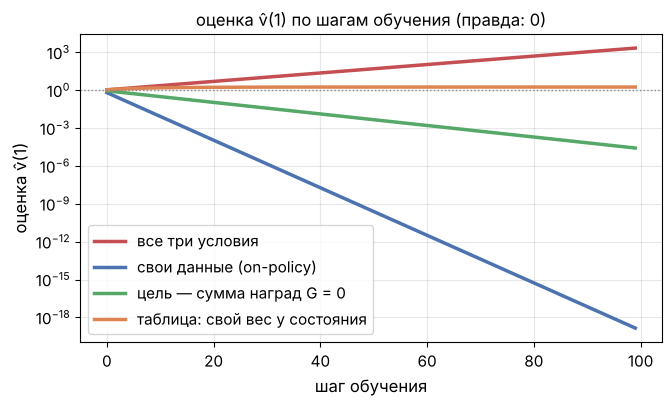

In [14]:
gamma, alpha = 0.9, 0.1

def step_all_three(v1):                 # общий вес: v̂(2) = 2·v1; цель 1.8·v1 — своя оценка; только переход 1 → 2
    return v1 + alpha * (gamma * 2 * v1 - v1)

def step_on_policy(v1):                 # свои данные: после 1 → 2 идёт и 2 → конец с целью 0 (признак состояния 2 равен 2)
    v1 = step_all_three(v1)
    return v1 + alpha * (0 - 2 * v1) * 2

def step_monte_carlo(v1):               # цель — сумма наград эпизода G = 0, своей оценки в ней нет
    return v1 + alpha * (0 - v1)

def step_table(v1):                     # таблица: у состояния 2 свой вес, он остаётся 2 — цель 1.8 не растёт
    return v1 + alpha * (gamma * 2.0 - v1)

curves = {}
for name, step in {"все три условия": step_all_three, "свои данные (on-policy)": step_on_policy,
                   "цель — сумма наград G = 0": step_monte_carlo, "таблица: свой вес у состояния": step_table}.items():
    v1, history = 1.0, []
    for _ in range(100):
        v1 = step(v1); history.append(v1)
    curves[name] = np.array(history)
    print(f"{name:32s} v̂(1) после 100 шагов: {v1:.2g}")
plot_w_curves(curves, title="оценка v̂(1) по шагам обучения (правда: 0)")
plt.show()

Ответ **C — вырастет до тысяч**: за шаг $w$ умножается на $1 + \alpha(2\gamma - 1) = 1.08$, и $1.08^{100} \approx 2200$.

**Почему так выходит.** Поднять $\hat v(1)$ можно только ручкой $w$, а она поднимает и $\hat v(2) = 2w$ — вдвое сильнее, и цель $1.8\,w$ убегает быстрее оценки. Опустить $\hat v(2)$ мог бы переход $2 \to$ конец с целью 0, но его в данных нет. Уберите любое из трёх условий — и пример сходится (три кривые на картинке).

> **Простыми словами.** Оценка подпирает сама себя: подняли $\hat v(1)$ — поднялась цель, подняли ещё — цель ещё выше. Остановить это может только настоящая награда, а её в данных нет. В песочнице на странице лекции условия выключаются по одному.

Эти три условия называют **смертельной триадой** (deadly triad). Сверим с ней всё, что обучали в курсе:

| условие | таблица Q-learning | Q-сеть по шагу подряд | Q-сеть + буфер | REINFORCE (лекция 5) |
|---|---|---|---|---|
| **аппроксимация** — общие веса у многих состояний | нет: у клетки свои числа | да | да | да |
| **бутстрэппинг** — в цели своя оценка $\hat v(s')$ | да | да | да | нет: вес — настоящие награды $G_t$ |
| **off-policy** — данные не той стратегии, которую оцениваем | да (лекция 4) | почти нет: только что сделанный шаг своей стратегии | да: журнал старых стратегий, вплоть до случайной | нет: свежие эпизоды своей стратегии |
| оценки разлетаются? | нет | нет (58–98) | **да** (1584–210 279) | нет |

Разлетается только столбец, где все три «да». Буфер хорош данными и плох тем же: он и есть третье условие.

**Одной строкой:** общие веса + своя оценка в цели + чужие данные могут развалить обучение даже при нулевых наградах — буфер опыта добавляет Q-сети третье условие.

## 5. Целевая сеть: неподвижная мишень. Это и есть DQN

**Главная идея: цель $y$ считает не сама обучаемая сеть, а её копия, которая медленно догоняет оригинал; цель перестаёт убегать, и вместе с буфером опыта это даёт DQN.**

Буфер оставляем, чиним убегающую цель. **Целевая сеть** (target network) $Q_{\bar\theta}$ — копия основной, и цель считает она:

$$
y \;=\; r + \gamma\,(1 - \text{конец})\, \max_{a'} Q_{\bar\theta}(s', a'), \qquad \bar\theta \;\leftarrow\; 0.99\, \bar\theta + 0.01\, \theta \ \ \text{после каждого шага}.
$$

Копия каждый шаг сдвигается к основной сети на 1 % — это `soft_update` и флаг `target` в `train_qnet`; в статье DQN копию переставляли целиком раз в 10 000 шагов, смысл тот же. Обучим оставшиеся два варианта и посмотрим на оценку старта у DQN: у основной сети и у копии.

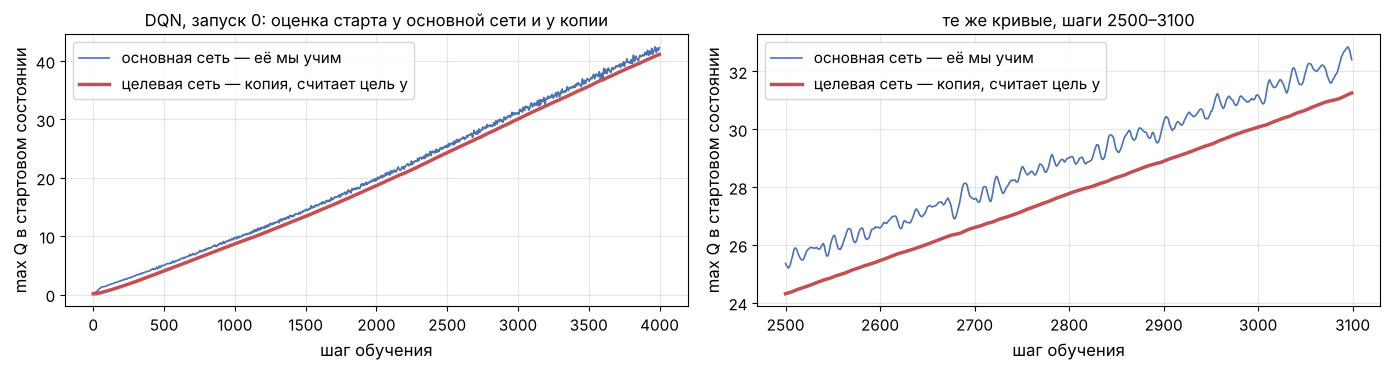

In [15]:
for name, replay, target in (("целевая сеть", False, True), ("буфер + целевая сеть (DQN)", True, True)):
    runs[name] = [train_qnet(seed, replay=replay, target=target) for seed in SEEDS]
    lengths[name] = np.array([run[0] for run in runs[name]])
    q_start[name] = np.array([run[1] for run in runs[name]])

trace = runs["буфер + целевая сеть (DQN)"][0][2]                 # запуск 0: первые 4000 шагов обучения
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
plot_q_lag(trace, ax=axes[0], title="DQN, запуск 0: оценка старта у основной сети и у копии")
plot_q_lag(trace, ax=axes[1], window=(2500, 3100), title="те же кривые, шаги 2500–3100")
plt.tight_layout(); plt.show()

Основная сеть дёргается на каждом шаге, копия идёт за ней гладко и с запозданием около сотни шагов: пока сеть делает шаг к цели, сама цель почти стоит на месте.

> **Простыми словами.** Мишень привязали к медленно ползущей копии стрелка: куда бы он ни дёрнулся, мишень за ним не прыгает.

**Вопрос 5 (голосуем).** Четыре варианта: буфер да/нет × целевая сеть да/нет. Какой будет держать шест дольше всех, не разгоняя оценки $Q$ до тысяч?

* **A.** только буфер;
* **B.** только целевая сеть;
* **C.** буфер и целевая сеть вместе;
* **D.** без приёмов.

по шагу подряд               шест в эпизодах 100–300:      [83. 75. 52.]   наибольшая оценка старта: [75. 98. 58.]
целевая сеть                 шест в эпизодах 100–300:      [33. 26. 32.]   наибольшая оценка старта: [45. 28. 36.]
буфер                        шест в эпизодах 100–300:   [348. 331. 206.]   наибольшая оценка старта: [  1584.   3698. 210279.]
буфер + целевая сеть (DQN)   шест в эпизодах 100–300:   [273. 416. 387.]   наибольшая оценка старта: [119. 114. 131.]


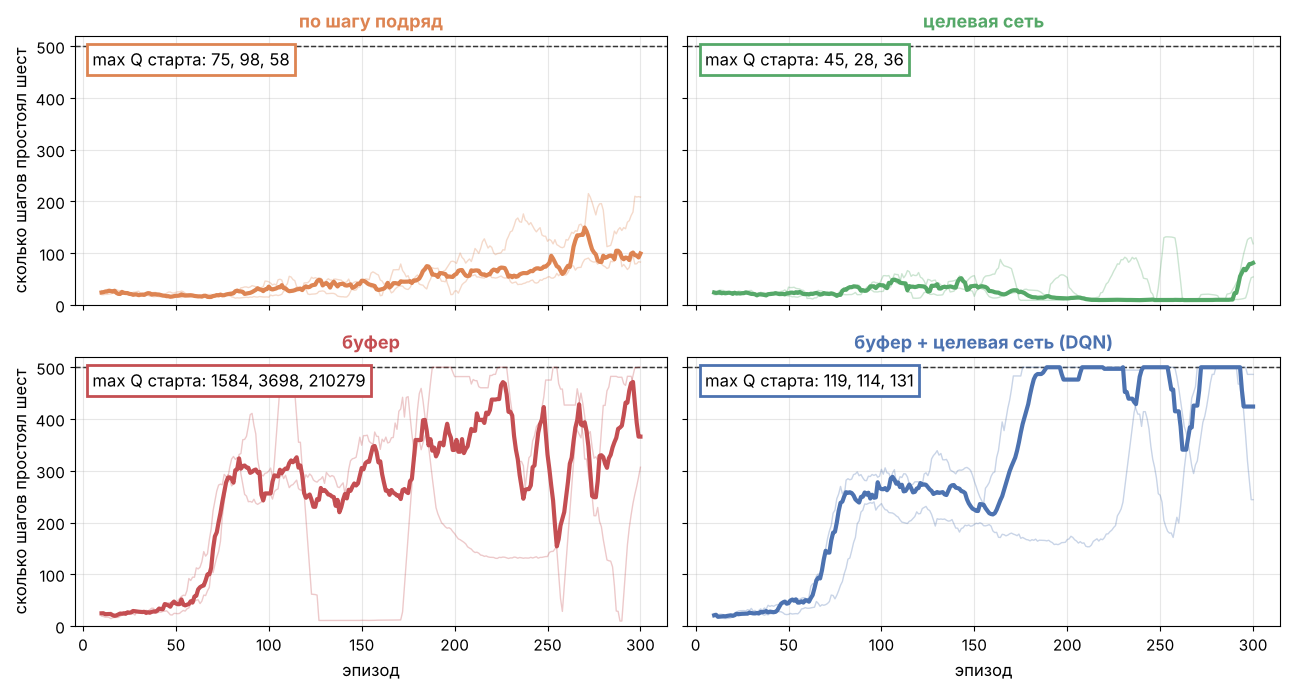

In [16]:
q_biggest = {name: np.abs(q).max(axis=1) for name, q in q_start.items()}
for name in ("по шагу подряд", "целевая сеть", "буфер", "буфер + целевая сеть (DQN)"):
    print(f"{name:28s} шест в эпизодах 100–{EPISODES}: {str(lengths[name][:, 100:].mean(axis=1).round(0)):>18s}"
          f"   наибольшая оценка старта: {q_biggest[name].round(0)}")
plot_grid_2x2(lengths, q_biggest)
plt.show()

Ответ **C — буфер и целевая сеть вместе**. DQN держит шест 273–416 шагов в эпизодах 100–300, а оценка старта — до 114–131: чуть выше предела 100, а не тысячи (почему выше — в разделе 6). Один буфер держит шест почти так же долго (206–348), но разгоняет оценки до тысяч и сотен тысяч, и обучение дёргается: тонкие линии запусков по дороге падают почти до нуля. Одна целевая сеть почти не учится: 26–33 шага, даже меньше, чем по шагу подряд, — без буфера примеров мало, они однообразные, а цель ещё и запаздывает.

> **Простыми словами.** Буфер даёт сети разнообразные примеры, целевая сеть — неподвижную мишень. По отдельности не работает: без буфера примеров мало и они однообразные, без целевой сети мишень убегает.

Так держит шест сеть из лучшего запуска DQN: в каждом состоянии — действие с наибольшим $Q$, без случайных шагов.

In [17]:
best = max(runs["буфер + целевая сеть (DQN)"], key=lambda run: run[0][-50:].mean())[-1]   # сеть лучшего запуска
states = play_greedy(best, seed=0)                       # эпизод без случайных шагов: действие с наибольшим Q
animate_cartpole(states, path="dqn_cartpole.gif", every=6, dpi=100)
print("шест простоял шагов:", len(states) - 1)

шест простоял шагов: 500


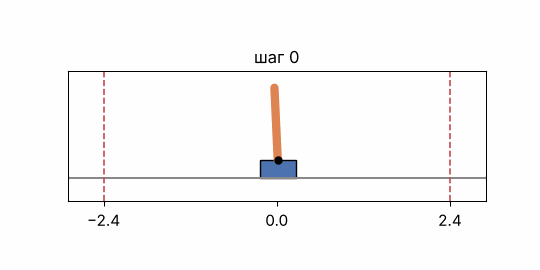

**Весь DQN в шести шагах** — то, что делает `train_qnet(seed, replay=True, target=True)`:

1. в состоянии $s$ выбрать действие ε-жадно по $Q_\theta$;
2. сделать шаг, положить $(s, a, r, s', \text{конец})$ в буфер;
3. взять из буфера случайную пачку;
4. посчитать цель $y = r + \gamma\,(1 - \text{конец}) \max_{a'} Q_{\bar\theta}(s', a')$ целевой сетью;
5. шаг градиента по $\big(y - Q_\theta(s, a)\big)^2$;
6. подтянуть копию: $\bar\theta \leftarrow 0.99\,\bar\theta + 0.01\,\theta$.

**Одной строкой:** DQN = Q-сеть + буфер опыта (разнообразные данные) + целевая сеть (неподвижная мишень).

## 6. ⏱ Улучшения DQN

**Главная идея: все улучшения DQN — о том, чтобы меньше опираться на завышенные или устаревшие собственные оценки.**

Оценка старта у DQN — до 131 при пределе 100: даже с целевой сетью $\max$ в цели завышает оценки, хотя и не до тысяч. Это смещение максимума из лекции 4, и первое улучшение — про него.

| улучшение | что меняет | зачем |
|---|---|---|
| Double DQN | действие в цели выбирает основная сеть, а оценивает целевая: $y = r + \gamma\, Q_{\bar\theta}\big(s', \arg\max_{a'} Q_\theta(s', a')\big)$ | смещение максимума (лекция 4): максимум шумных оценок завышен; вторая оценка уже есть — целевая сеть |
| Dueling DQN | сеть отдельно оценивает, насколько хорошо состояние, $V(s)$, и насколько лучше каждое действие, $A(s, a)$ | там, где действие почти не важно, $V$ учится по всем действиям сразу |
| Prioritized replay | из буфера чаще берутся переходы с большой ошибкой $\lvert y - Q \rvert$ | учимся там, где сеть ошибается сильнее |
| n-step | в цели $n$ настоящих наград, потом оценка | меньше опоры на свою оценку |
| Rainbow | всё вместе и ещё два приёма | на Atari лучше каждого улучшения по отдельности |

**Одной строкой:** улучшения DQN уменьшают завышение и опору на собственные оценки.

## 7. Итоги и где это работает

1. **Таблица учит каждую клетку отдельно:** за 300 эпизодов обновились 8 % клеток из 1296, шест стоит 43–61 шагов.
2. **Q-сеть обобщает:** один шаг сдвигает $Q$ почти на всей плоскости, оценка есть в каждой точке — но по шагу подряд сеть учится медленно (52–83 шагов).
3. **Буфер опыта** перемешивает данные и ускоряет обучение, но замыкает **смертельную триаду** — общие веса, своя оценка в цели, чужие данные: оценка старта выросла до 1584–210 279 при пределе 100.
4. **Целевая сеть** — медленная копия основной — держит цель на месте. **DQN = Q-сеть + буфер + целевая сеть:** в эпизодах 100–300 шест стоит 273–416 шагов, оценка старта до 114–131 — без разлёта до тысяч; лучшая сеть без случайных шагов держит шест все 500 шагов.
5. **Почему сеть лучше таблицы:** обобщает похожие состояния, не требует ручной сетки, работает с картинками. Плата — неустойчивость, её лечат буфер и целевая сеть.

**Где это работает:** игры Atari — DQN (Mnih и др., 2015) по четырём кадрам экрана $84 \times 84$ научился 49 играм одной программой; нарды — TD-Gammon (Тезауро, 1992) с сетью-оценкой позиции, предшественник DQN; рекомендации — DQN выбирает, что показать, когда вариантов немного, а состояние — вектор признаков пользователя.

> **Простыми словами — вся лекция.** Таблица заучивает билеты, сеть понимает правило. Но сеть, которая учится по собственным оценкам на старых данных, может «убедить сама себя» в бессмыслице. DQN не даёт ей этого сделать: учит на перемешанных примерах и сверяется с медленной копией себя.

Словарь лекции: **Q-сеть, обобщение, цель $y$, буфер опыта (experience replay), смертельная триада (аппроксимация, бутстрэппинг, off-policy), целевая сеть (target network), DQN, Double DQN**.

## Литература

* Mnih V. и др. *Human-level control through deep reinforcement learning*. Nature, 2015 — DQN на Atari.
* Саттон Р., Барто Э. *Обучение с подкреплением*, 2-е изд., глава 11 (пример с $w$ и $2w$ — раздел 11.2, смертельная триада — раздел 11.3). [incompleteideas.net/book/the-book-2nd.html](http://incompleteideas.net/book/the-book-2nd.html)
* van Hasselt H., Guez A., Silver D. *Deep reinforcement learning with double Q-learning*. AAAI, 2016 — Double DQN.
* Hessel M. и др. *Rainbow: combining improvements in deep reinforcement learning*. AAAI, 2018.
* [Учебник по машинному обучению ШАД, глава «Обучение с подкреплением»](https://education.yandex.ru/handbook/ml/article/obuchenie-s-podkrepleniem).

## На семинаре и дома

* **Домашка блока 3** — дедлайн объявит преподаватель.

In [18]:
print(f"ноутбук посчитался за {(time.time() - start_time) / 60:.0f} мин")

ноутбук посчитался за 10 мин
